# Homework 5.2 - Steps 2-4

## Lorenz Trajectories, Phase-Space Discretization, and Token Sequences

This notebook constructs the dynamical-system dataset used by the rest of Homework 5.2.

The workflow is

$$
\text{initial condition}
\longrightarrow
\text{continuous Lorenz trajectory}
\longrightarrow
\text{phase-space box}
\longrightarrow
\text{token sequence}.
$$

Each independently simulated trajectory is treated as one training, validation, or test "book." No transition is ever created between the end of one book and the beginning of another.

The Lorenz equations are

$$
\dot{x}=10(y-x),
$$

$$
\dot{y}=x(28-z)-y,
$$

$$
\dot{z}=xy-\frac{8}{3}z.
$$

## Experimental design

We generate independent trajectories from different seeded initial conditions.

The fixed baseline design is:

- 40 training trajectories;
- 10 validation trajectories;
- 10 test trajectories;
- 5 time units of transient dynamics discarded;
- 25 time units retained per trajectory;
- fixed sampling interval

$$
\Delta t=0.02.
$$

The transient is discarded so that the recorded portion primarily samples attracting dynamics rather than arbitrary initial-condition relaxation.

The train/validation/test assignment is made before any discretization is fitted.

The phase-space bounds are estimated from the **training trajectories only** and then expanded by a fixed 5% margin. Validation and test trajectories do not determine the discretization.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw5_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw5_2"

TRAJECTORY_DIR = DATA_DIR / "trajectories"
TOKEN_DIR = DATA_DIR / "token_books"

for path in [
    DATA_DIR,
    RESULT_DIR,
    TRAJECTORY_DIR / "train",
    TRAJECTORY_DIR / "validation",
    TRAJECTORY_DIR / "test",
    TOKEN_DIR / "train",
    TOKEN_DIR / "validation",
    TOKEN_DIR / "test",
]:
    path.mkdir(parents=True, exist_ok=True)

SEED = 63852

SIGMA = 10.0
RHO = 28.0
BETA = 8.0 / 3.0

N_TRAIN = 40
N_VALIDATION = 10
N_TEST = 10

TRANSIENT_TIME = 5.0
RECORD_TIME = 25.0
DT = 0.02

BASELINE_BINS = (12, 12, 12)
BOUND_PADDING_FRACTION = 0.05

rng = np.random.default_rng(SEED)

print("Project root:", PROJECT_ROOT.resolve())
print("Data folder:", DATA_DIR.resolve())
print("Result image folder:", RESULT_DIR.resolve())

Project root: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2
Data folder: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2
Result image folder: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2


## Step 2: Generate independent Lorenz trajectories

For each initial condition

$$
X_0=(x_0,y_0,z_0),
$$

the Lorenz ODE is integrated numerically.

The initial conditions are sampled independently from the fixed box

$$
x_0,y_0\in[-20,20],
\qquad
z_0\in[5,35].
$$

The same numerical tolerances are used for every trajectory.

In [2]:
def lorenz_rhs(t, state):
    x, y, z = state

    dx = SIGMA * (y - x)
    dy = x * (RHO - z) - y
    dz = x * y - BETA * z

    return np.array([dx, dy, dz], dtype=float)


def draw_initial_condition(rng):
    return np.array(
        [
            rng.uniform(-20.0, 20.0),
            rng.uniform(-20.0, 20.0),
            rng.uniform(5.0, 35.0),
        ],
        dtype=float,
    )


def simulate_trajectory(initial_condition):
    total_time = TRANSIENT_TIME + RECORD_TIME

    t_eval = np.arange(
        0.0,
        total_time + 0.5 * DT,
        DT,
    )

    solution = solve_ivp(
        lorenz_rhs,
        t_span=(0.0, total_time),
        y0=initial_condition,
        t_eval=t_eval,
        method="DOP853",
        rtol=1e-9,
        atol=1e-11,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    keep = solution.t >= TRANSIENT_TIME - 1e-12

    time = solution.t[keep] - TRANSIENT_TIME
    states = solution.y[:, keep].T

    return time, states


split_sizes = {
    "train": N_TRAIN,
    "validation": N_VALIDATION,
    "test": N_TEST,
}

trajectory_manifest = []
book_id = 0

for split_name, count in split_sizes.items():
    for split_index in range(count):
        initial_condition = draw_initial_condition(rng)
        time, states = simulate_trajectory(initial_condition)

        output_path = (
            TRAJECTORY_DIR
            / split_name
            / f"book_{split_index:03d}.npz"
        )

        np.savez_compressed(
            output_path,
            time=time,
            states=states,
            initial_condition=initial_condition,
        )

        trajectory_manifest.append({
            "global_book_id": book_id,
            "split": split_name,
            "split_book_id": split_index,
            "samples": len(time),
            "initial_x": initial_condition[0],
            "initial_y": initial_condition[1],
            "initial_z": initial_condition[2],
            "file": str(output_path.relative_to(PROJECT_ROOT)),
        })

        book_id += 1

manifest_df = pd.DataFrame(trajectory_manifest)

manifest_path = DATA_DIR / "trajectory_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

print(manifest_df.groupby("split")["samples"].agg(["count", "min", "max"]))
print()
print("Saved:", manifest_path.resolve())

            count   min   max
split                        
test           10  1251  1251
train          40  1251  1251
validation     10  1251  1251

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\trajectory_manifest.csv


## Verify and visualize the continuous trajectories

The figures below are construction checks. They do not enter model fitting.

A true Lorenz trajectory should remain in the familiar two-lobed attracting region after the transient.

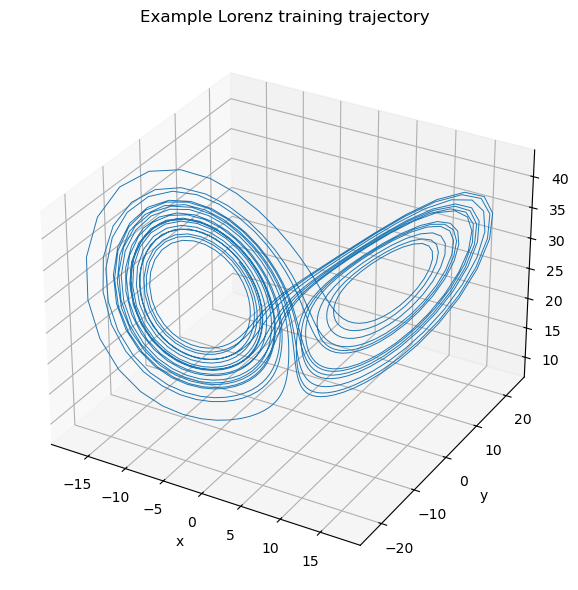

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step2_example_lorenz_3d.png


In [3]:
example = np.load(
    TRAJECTORY_DIR / "train" / "book_000.npz"
)

example_states = example["states"]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    example_states[:, 0],
    example_states[:, 1],
    example_states[:, 2],
    linewidth=0.7,
)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Example Lorenz training trajectory")
plt.tight_layout()

path = RESULT_DIR / "step2_example_lorenz_3d.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path.resolve())

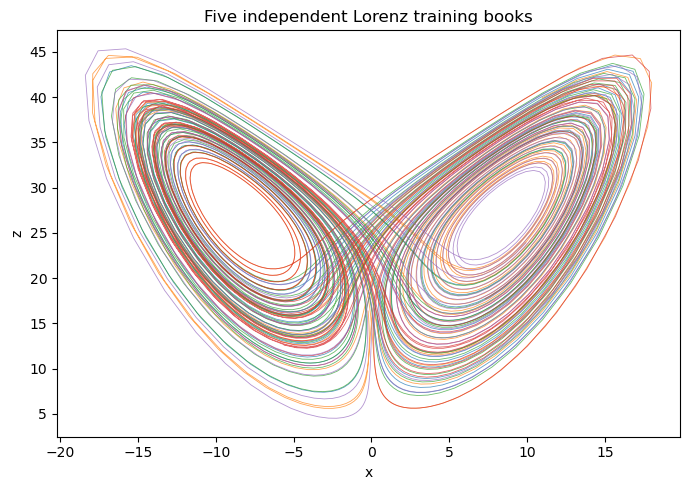

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step2_five_training_books_xz.png


In [4]:
plt.figure(figsize=(7, 5))

for book_index in range(5):
    trajectory = np.load(
        TRAJECTORY_DIR
        / "train"
        / f"book_{book_index:03d}.npz"
    )

    states = trajectory["states"]

    plt.plot(
        states[:, 0],
        states[:, 2],
        linewidth=0.6,
        alpha=0.7,
    )

plt.xlabel("x")
plt.ylabel("z")
plt.title("Five independent Lorenz training books")
plt.tight_layout()

path = RESULT_DIR / "step2_five_training_books_xz.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path.resolve())

# Step 3: Discretize phase space into boxes

For the baseline experiment, the three coordinates are divided uniformly into

$$
N_x=N_y=N_z=12
$$

bins.

Therefore the number of possible boxes is

$$
|\mathcal V_{\text{possible}}|
=
N_xN_yN_z
=
12^3
=
1728.
$$

Every box receives one token ID, whether or not that box is visited during training.

The **observed vocabulary** is the subset of these tokens that actually occurs in the trajectories.

Increasing the number of bins increases the possible vocabulary multiplicatively:

$$
|\mathcal V_{\text{possible}}|
=
N_xN_yN_z.
$$

Task 10 will later vary this resolution while holding the physical phase-space bounds fixed.

In [5]:
def load_states(split_name):
    arrays = []

    for book_index in range(split_sizes[split_name]):
        data = np.load(
            TRAJECTORY_DIR
            / split_name
            / f"book_{book_index:03d}.npz"
        )

        arrays.append(data["states"])

    return arrays


train_state_books = load_states("train")
all_train_states = np.vstack(train_state_books)

training_min = all_train_states.min(axis=0)
training_max = all_train_states.max(axis=0)
span = training_max - training_min

lower_bounds = (
    training_min
    - BOUND_PADDING_FRACTION * span
)

upper_bounds = (
    training_max
    + BOUND_PADDING_FRACTION * span
)

nx, ny, nz = BASELINE_BINS

x_edges = np.linspace(
    lower_bounds[0],
    upper_bounds[0],
    nx + 1,
)

y_edges = np.linspace(
    lower_bounds[1],
    upper_bounds[1],
    ny + 1,
)

z_edges = np.linspace(
    lower_bounds[2],
    upper_bounds[2],
    nz + 1,
)

print("Training-only raw minimum:", training_min)
print("Training-only raw maximum:", training_max)
print("Padded lower bounds:", lower_bounds)
print("Padded upper bounds:", upper_bounds)
print("Possible vocabulary size:", nx * ny * nz)

Training-only raw minimum: [-18.67329517 -25.35408715   2.84745446]
Training-only raw maximum: [18.88264452 26.04691725 46.60640316]
Padded lower bounds: [-20.55109215 -27.92413737   0.65950703]
Padded upper bounds: [20.7604415  28.61696747 48.79435059]
Possible vocabulary size: 1728


In [6]:
def coordinate_to_bin(values, edges):
    raw = np.searchsorted(
        edges,
        values,
        side="right",
    ) - 1

    out_of_range = (
        (values < edges[0])
        | (values > edges[-1])
    )

    indices = np.clip(
        raw,
        0,
        len(edges) - 2,
    )

    return indices.astype(int), out_of_range


def states_to_tokens(states):
    ix, out_x = coordinate_to_bin(
        states[:, 0],
        x_edges,
    )

    iy, out_y = coordinate_to_bin(
        states[:, 1],
        y_edges,
    )

    iz, out_z = coordinate_to_bin(
        states[:, 2],
        z_edges,
    )

    tokens = (
        ix * (ny * nz)
        + iy * nz
        + iz
    )

    clipped = out_x | out_y | out_z

    return (
        tokens.astype(int),
        ix,
        iy,
        iz,
        clipped,
    )


def token_to_indices(token):
    ix = token // (ny * nz)
    remainder = token % (ny * nz)
    iy = remainder // nz
    iz = remainder % nz
    return ix, iy, iz


def token_center(token):
    ix, iy, iz = token_to_indices(token)

    x_center = 0.5 * (
        x_edges[ix] + x_edges[ix + 1]
    )

    y_center = 0.5 * (
        y_edges[iy] + y_edges[iy + 1]
    )

    z_center = 0.5 * (
        z_edges[iz] + z_edges[iz + 1]
    )

    return np.array(
        [x_center, y_center, z_center],
        dtype=float,
    )

# Step 4: Convert every trajectory into a token sequence

Each sampled continuous state

$$
X(t_i)=(x_i,y_i,z_i)
$$

is mapped to exactly one box and therefore one token:

$$
X(t_1),X(t_2),\ldots
\longrightarrow
a_1,a_2,\ldots.
$$

The same fitted discretization is applied to training, validation, and test books.

If a held-out point lies slightly outside the training-fitted padded bounds, it is clipped to the nearest boundary box and the event is counted. The clipping rate is reported rather than hidden.

In [7]:
token_manifest = []
all_tokens_by_split = {
    "train": [],
    "validation": [],
    "test": [],
}

for split_name, count in split_sizes.items():
    for book_index in range(count):
        trajectory = np.load(
            TRAJECTORY_DIR
            / split_name
            / f"book_{book_index:03d}.npz"
        )

        time = trajectory["time"]
        states = trajectory["states"]

        (
            tokens,
            ix,
            iy,
            iz,
            clipped,
        ) = states_to_tokens(states)

        output_path = (
            TOKEN_DIR
            / split_name
            / f"book_{book_index:03d}.csv"
        )

        frame = pd.DataFrame({
            "sample_index": np.arange(len(tokens)),
            "time": time,
            "token": tokens,
            "ix": ix,
            "iy": iy,
            "iz": iz,
            "clipped_to_training_bounds": clipped,
        })

        frame.to_csv(output_path, index=False)

        all_tokens_by_split[
            split_name
        ].append(tokens)

        token_manifest.append({
            "split": split_name,
            "book": book_index,
            "samples": len(tokens),
            "distinct_tokens": len(np.unique(tokens)),
            "clipped_samples": int(clipped.sum()),
            "clipped_fraction": float(clipped.mean()),
            "file": str(output_path.relative_to(PROJECT_ROOT)),
        })

token_manifest_df = pd.DataFrame(token_manifest)

token_manifest_path = DATA_DIR / "token_book_manifest.csv"
token_manifest_df.to_csv(token_manifest_path, index=False)

print(token_manifest_df.groupby("split")[
    ["samples", "distinct_tokens", "clipped_samples"]
].agg({
    "samples": ["count", "sum"],
    "distinct_tokens": ["min", "max"],
    "clipped_samples": "sum",
}))

print()
print("Saved:", token_manifest_path.resolve())

           samples        distinct_tokens      clipped_samples
             count    sum             min  max             sum
split                                                         
test            10  12510             118  183               0
train           40  50040             115  180               0
validation      10  12510             134  178               0

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\token_book_manifest.csv


In [8]:
possible_vocabulary = nx * ny * nz

train_tokens_flat = np.concatenate(
    all_tokens_by_split["train"]
)

validation_tokens_flat = np.concatenate(
    all_tokens_by_split["validation"]
)

test_tokens_flat = np.concatenate(
    all_tokens_by_split["test"]
)

observed_train = np.unique(train_tokens_flat)

observed_all = np.unique(
    np.concatenate(
        [
            train_tokens_flat,
            validation_tokens_flat,
            test_tokens_flat,
        ]
    )
)

print("Possible vocabulary size:", possible_vocabulary)
print("Observed training vocabulary:", len(observed_train))
print("Observed overall vocabulary:", len(observed_all))

for split_name in ["train", "validation", "test"]:
    split_rows = token_manifest_df[
        token_manifest_df["split"] == split_name
    ]

    total_samples = int(split_rows["samples"].sum())
    total_clipped = int(split_rows["clipped_samples"].sum())

    print(
        f"{split_name:<11} "
        f"clipped {total_clipped:,}/{total_samples:,} "
        f"= {total_clipped / total_samples:.6%}"
    )

Possible vocabulary size: 1728
Observed training vocabulary: 250
Observed overall vocabulary: 257
train       clipped 0/50,040 = 0.000000%
validation  clipped 0/12,510 = 0.000000%
test        clipped 0/12,510 = 0.000000%


## Save the complete box vocabulary

The vocabulary table stores every possible baseline box and its geometric center.

This table will later allow generated token sequences to be mapped back to approximate continuous coordinates.

In [9]:
box_rows = []

train_token_counts = pd.Series(
    train_tokens_flat
).value_counts()

validation_token_counts = pd.Series(
    validation_tokens_flat
).value_counts()

test_token_counts = pd.Series(
    test_tokens_flat
).value_counts()

for token in range(possible_vocabulary):
    ix, iy, iz = token_to_indices(token)
    center = token_center(token)

    box_rows.append({
        "token": token,
        "ix": ix,
        "iy": iy,
        "iz": iz,
        "x_center": center[0],
        "y_center": center[1],
        "z_center": center[2],
        "train_frequency": int(train_token_counts.get(token, 0)),
        "validation_frequency": int(validation_token_counts.get(token, 0)),
        "test_frequency": int(test_token_counts.get(token, 0)),
    })

box_vocab_df = pd.DataFrame(box_rows)

box_vocab_path = DATA_DIR / "baseline_box_vocabulary.csv"
box_vocab_df.to_csv(box_vocab_path, index=False)

print("Saved:", box_vocab_path.resolve())

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\baseline_box_vocabulary.csv


In [10]:
configuration = {
    "seed": SEED,
    "lorenz_parameters": {
        "sigma": SIGMA,
        "rho": RHO,
        "beta": BETA,
    },
    "trajectory_counts": {
        "train": N_TRAIN,
        "validation": N_VALIDATION,
        "test": N_TEST,
    },
    "transient_time": TRANSIENT_TIME,
    "record_time": RECORD_TIME,
    "sampling_interval_dt": DT,
    "baseline_bins": {
        "x": nx,
        "y": ny,
        "z": nz,
    },
    "possible_vocabulary_size": possible_vocabulary,
    "observed_training_vocabulary_size": int(len(observed_train)),
    "observed_overall_vocabulary_size": int(len(observed_all)),
    "training_fitted_lower_bounds": lower_bounds.tolist(),
    "training_fitted_upper_bounds": upper_bounds.tolist(),
    "bound_padding_fraction": BOUND_PADDING_FRACTION,
}

configuration_path = DATA_DIR / "baseline_configuration.json"

configuration_path.write_text(
    json.dumps(configuration, indent=2),
    encoding="utf-8",
)

print("Saved:", configuration_path.resolve())

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\data\hw5_2\baseline_configuration.json


## Token-frequency visualization

A fine discretization can create many rare boxes. The token-frequency distribution is therefore an important diagnostic for later Markov models.

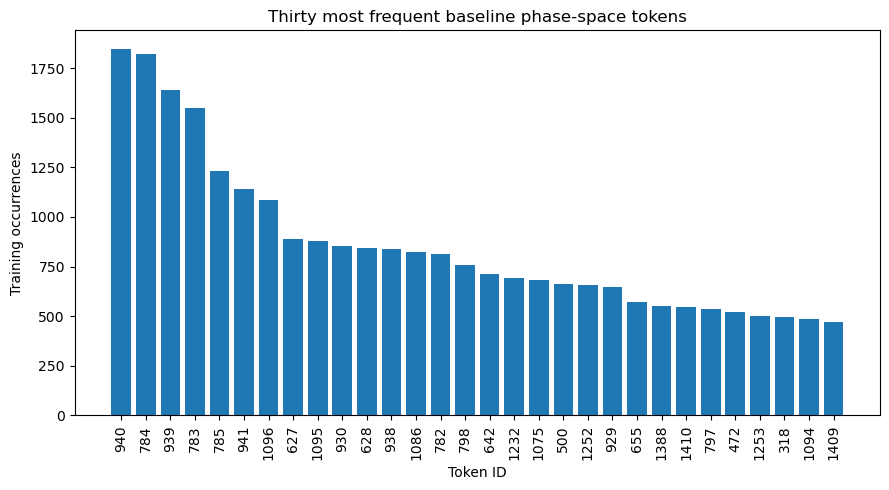

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step4_top30_token_frequencies.png


In [11]:
top_counts = (
    train_token_counts
    .sort_values(ascending=False)
    .head(30)
)

plt.figure(figsize=(9, 5))

plt.bar(
    [str(int(token)) for token in top_counts.index],
    top_counts.values,
)

plt.xlabel("Token ID")
plt.ylabel("Training occurrences")
plt.title("Thirty most frequent baseline phase-space tokens")
plt.xticks(rotation=90)
plt.tight_layout()

path = RESULT_DIR / "step4_top30_token_frequencies.png"

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Steps 2-4 outputs

### Continuous trajectory data

`data/hw5_2/trajectories/`

with independent train, validation, and test books.

### Token books

`data/hw5_2/token_books/`

with one token sequence per trajectory.

### Metadata

- `trajectory_manifest.csv`
- `token_book_manifest.csv`
- `baseline_configuration.json`
- `baseline_box_vocabulary.csv`

### Result images

- `step2_example_lorenz_3d.png`
- `step2_five_training_books_xz.png`
- `step4_top30_token_frequencies.png`

The next notebook fits Markov and higher-order context models using only the training token books.